In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    silhouette_score
)

df = pd.read_csv("battery_observations.csv", index_col=0)
meta = pd.read_csv("battery_metadata.csv", index_col=0)
df2 = df.join(meta[["climate_zone", "chemistry"]])
df2 = df2.sort_values(["battery_id", "cycle_index"])
df2 = df2.reset_index()
meta = meta.reset_index()
g = lambda x: int(x.split('-')[-1])
df2["battery_id"] = df2["battery_id"].apply(g)
meta["battery_id"] = meta["battery_id"].apply(g)
battery_ids = list(set(df2["battery_id"]))
materials = list(set(meta["chemistry"]))
climate_zones = list(set(meta["climate_zone"]))
labels = list(set(df2["degradation_status"]))

train_labels = pd.read_csv("train_batteries.csv")["battery_id"].apply(g)
val_labels = pd.read_csv("validation_batteries.csv")["battery_id"].apply(g)

train = df2[df2["battery_id"].isin(train_labels)]
val = df2[df2["battery_id"].isin(val_labels)]

I0000 00:00:1795075917.571518    6926 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795075917.853218    6926 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795075919.356833    6926 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
"""
ideas:
-standardize features and do embedding for categorical features, 2-3 hidden layers with batchnorm, relu, dropout and end with 4-element softmax
-same body, but predicting P(y > category) for category = normal, moderate, severe (3 probabilities).
-windowed sequence model, using teacher-student. loss = a*CE(y,student(x_t))+(1-a)*KL(teacher_probs | student_probs) (CE = cross entropy)
impact of a:
High α (0.7–1.0) is safer if the teacher is weak, overfit or poorly calibrated, since the labels dominate. If the teacher’s soft labels are nearly one-hot (e.g. it was trained on the same rows), the KL term adds almost nothing anyway.
Low α (0.1–0.4) helps when the teacher is clearly better than a plain student and its soft labels are informative (e.g. out-of-fold, with temperature). It also helps if the hard labels are noisy, because the teacher smooths them.


"""

'\nideas:\n-standardize features and do embedding for categorical features, 2-3 hidden layers with batchnorm, relu, dropout and end with 4-element softmax\n-same body, but predicting P(y > category) for category = normal, moderate, severe (3 probabilities).\n-windowed sequence model, using teacher-student. loss = a*CE(y,student(x_t))+(1-a)*KL(teacher_probs | student_probs) (CE = cross entropy)\nimpact of a:\nHigh α (0.7–1.0) is safer if the teacher is weak, overfit or poorly calibrated, since the labels dominate. If the teacher’s soft labels are nearly one-hot (e.g. it was trained on the same rows), the KL term adds almost nothing anyway.\nLow α (0.1–0.4) helps when the teacher is clearly better than a plain student and its soft labels are informative (e.g. out-of-fold, with temperature). It also helps if the hard labels are noisy, because the teacher smooths them.\n\n\n'

In [3]:
features_A = [
    "battery_age_days",
    "equivalent_full_cycles",
    "internal_resistance_mOhm",
    "cumulative_high_temp_hours",
]
features_B = features_A + ["cycle_index"]
features_C = features_B + ["ambient_temp_c"]
features = [features_A, features_B, features_C] # all feature sets together
label_names = ["A", "B", "C"]

In [4]:
def build_mlp(n_num, hidden=(128, 64, 32), dropout=0.3, lr=1e-3):
    inp = keras.Input(shape=(n_num,), name="num")
    x = inp
    for h in hidden:
        x = layers.Dense(h, use_bias=False)(x)      # BN supplies the bias
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.Dropout(dropout)(x)
    out = layers.Dense(4, activation="softmax", name="status")(x)

    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

def train_model(model, X_train, X_val, y_train, y_val, hidden_dim, learning_rate, dropout_rate):
    cw = compute_class_weight("balanced", classes=np.arange(4), y=y_train)
    class_weight = dict(enumerate(cw))

    # ---------- 6. training ----------
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5),
    ]

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=200, batch_size=256,
        class_weight=class_weight,
        callbacks=callbacks,
        verbose=2,
    )

    val_loss = model.evaluate(X_val, y_val, verbose=0)
    val_pred = model.predict(X_val).argmax(axis=1)
    print('shape:', val_pred.shape)
    metrics = {
        "hidden_dim": hidden_dim,
        "dropout_rate": dropout_rate,
        "learning_rate": learning_rate,
        "val_loss": val_loss,
        "ARI": adjusted_rand_score(y_val, val_pred),
        "NMI": normalized_mutual_info_score(y_val, val_pred),
        "accuracy": accuracy_score(y_val, val_pred),
        "macro_F1": f1_score(
            y_val, val_pred,
            average="macro",
            zero_division=0
        ),
        "val_pred": val_pred
    }
    metrics["val_error"] = 1 - metrics["accuracy"]
    return metrics
    

Epoch 1/200


E0000 00:00:1795075920.354483    6926 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1795075920.389526    6926 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


478/478 - 2s - 4ms/step - accuracy: 0.6345 - loss: 0.9138 - val_accuracy: 0.6354 - val_loss: 0.7288 - learning_rate: 0.0100
Epoch 2/200
478/478 - 1s - 2ms/step - accuracy: 0.6837 - loss: 0.8118 - val_accuracy: 0.5746 - val_loss: 0.7443 - learning_rate: 0.0100
Epoch 3/200
478/478 - 1s - 2ms/step - accuracy: 0.6665 - loss: 0.7909 - val_accuracy: 0.6911 - val_loss: 0.7041 - learning_rate: 0.0100
Epoch 4/200
478/478 - 1s - 2ms/step - accuracy: 0.6948 - loss: 0.7780 - val_accuracy: 0.6943 - val_loss: 0.7064 - learning_rate: 0.0100
Epoch 5/200
478/478 - 1s - 2ms/step - accuracy: 0.6869 - loss: 0.7636 - val_accuracy: 0.5846 - val_loss: 0.8359 - learning_rate: 0.0100
Epoch 6/200
478/478 - 1s - 2ms/step - accuracy: 0.6898 - loss: 0.7540 - val_accuracy: 0.5839 - val_loss: 0.8606 - learning_rate: 0.0100
Epoch 7/200
478/478 - 1s - 2ms/step - accuracy: 0.6909 - loss: 0.7506 - val_accuracy: 0.6840 - val_loss: 0.6790 - learning_rate: 0.0100
Epoch 8/200
478/478 - 1s - 2ms/step - accuracy: 0.6895 - los

AttributeError: 'numpy.ndarray' object has no attribute 'spines'

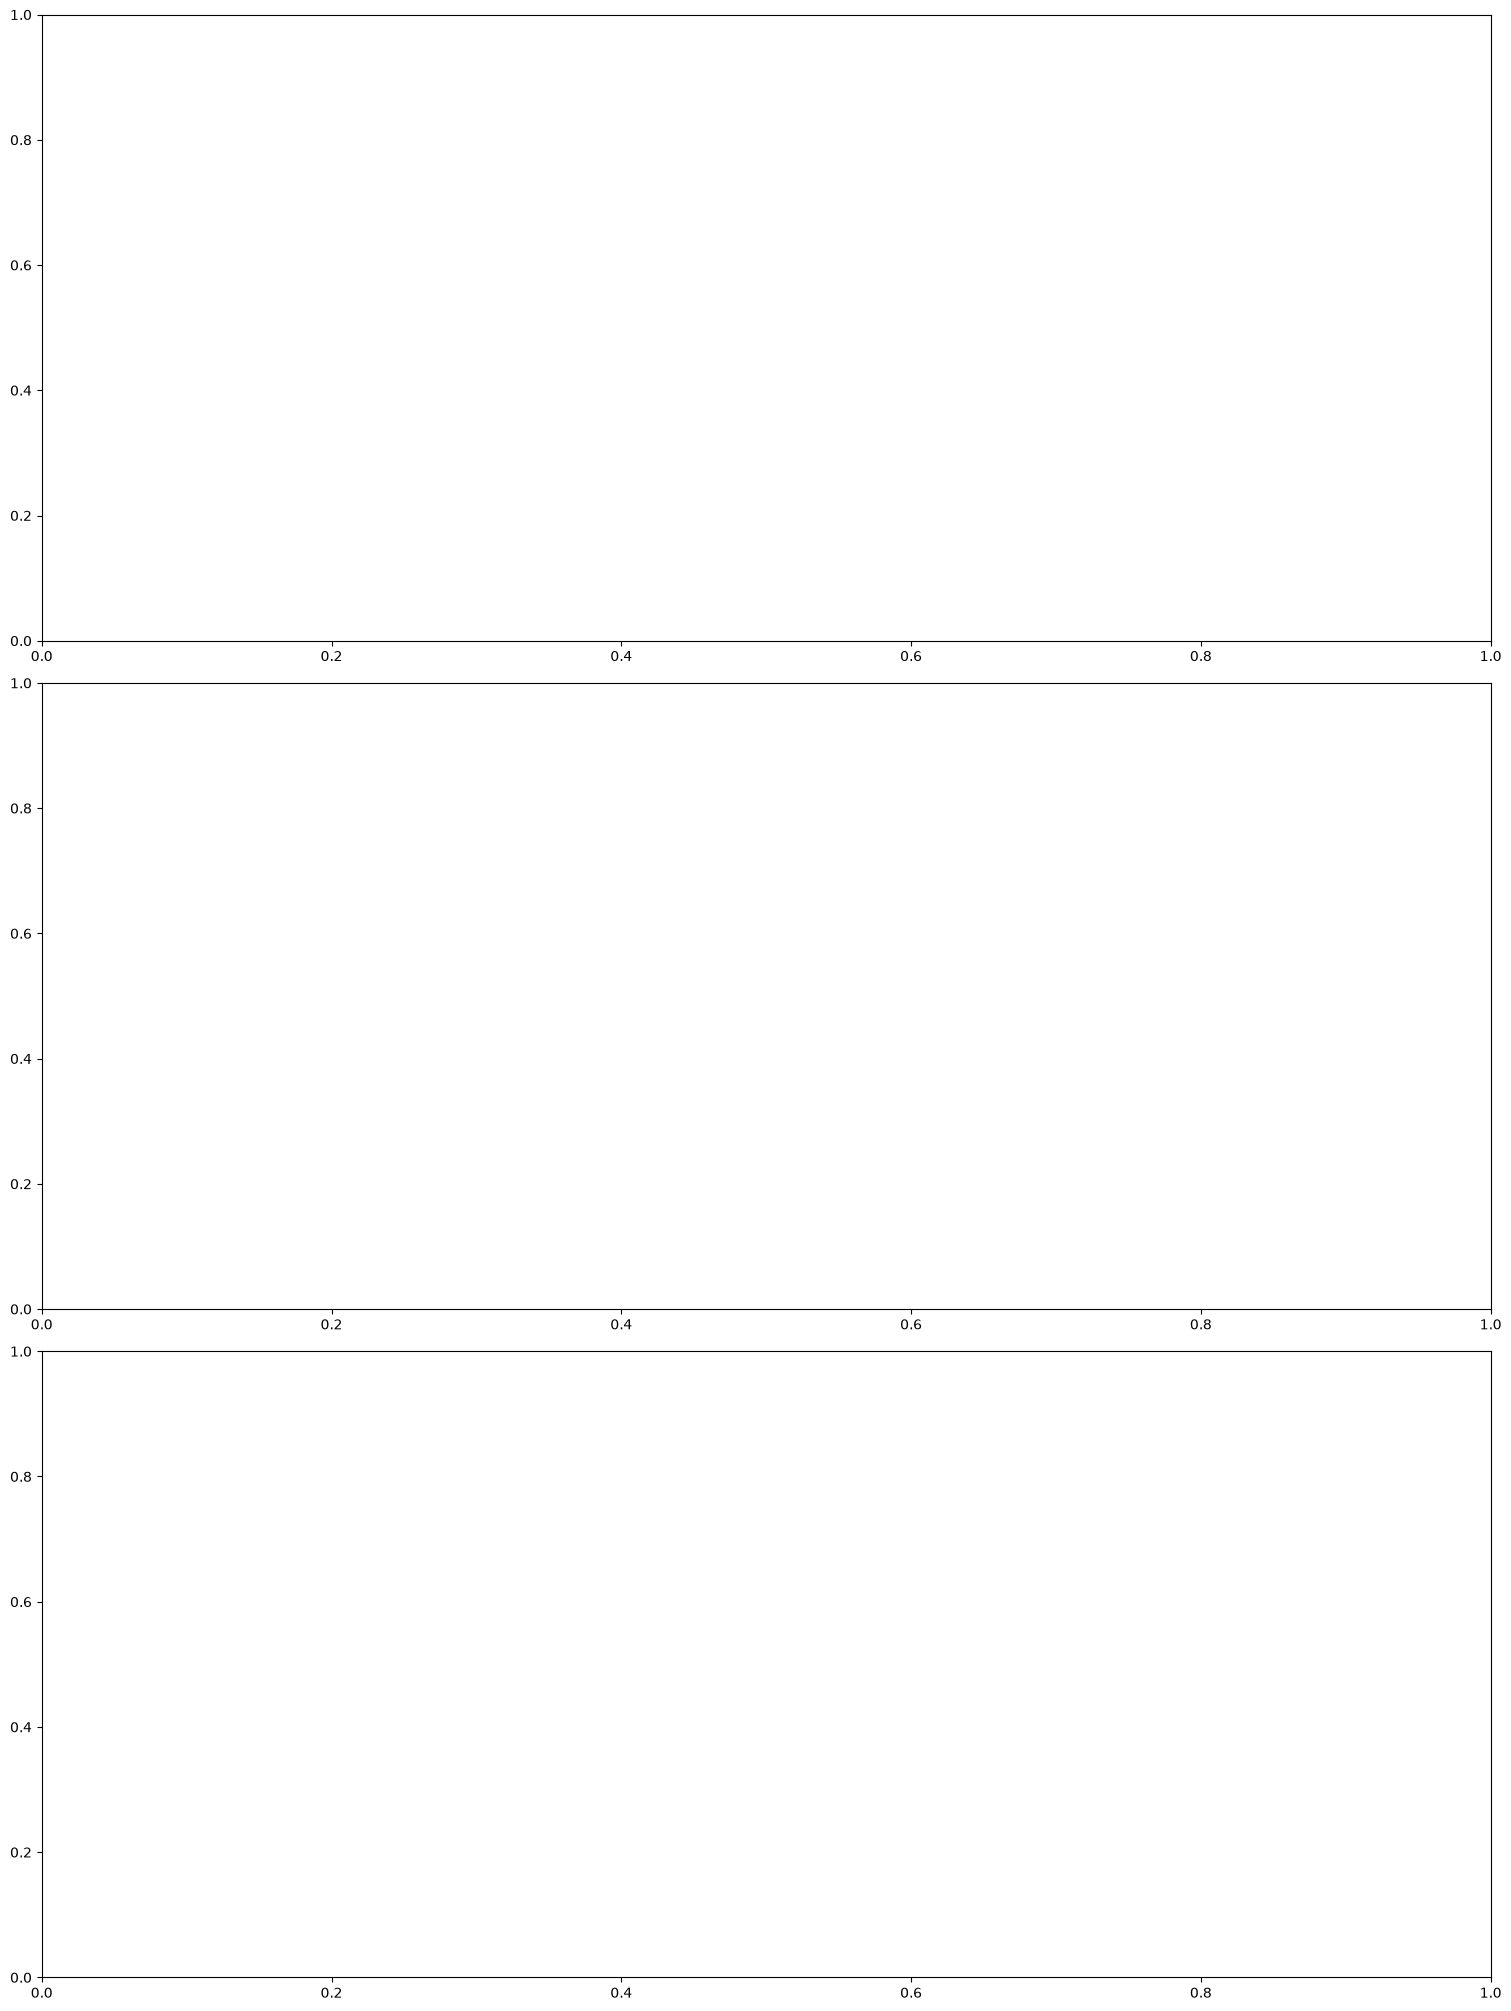

In [ ]:
from itertools import product
import seaborn as sns
from pathlib import Path

HIDDEN_DIMS = [
    (128, 64),
    (64, 32, 16),
    (128, 64, 32)
]
DROPOUT_RATES = [0.0, 0.15]
LEARNING_RATES = [1e-2, 1e-3, 1e-5]

# HIDDEN_DIMS = [(128, 64)]
# DROPOUT_RATES = [0.10]
# LEARNING_RATES = [1e-2]

class_names = ["Normal", "Moderate", "Severe", "Critical"]

hidden_dim_mapping = {HIDDEN_DIMS[x]:x for x in range(len(HIDDEN_DIMS))}
dropout_rate_mapping = {DROPOUT_RATES[x]:x for x in range(len(DROPOUT_RATES))}
learning_rate_mapping = {LEARNING_RATES[x]:x for x in range(len(LEARNING_RATES))}

class_names_mapping = {class_names[x]:x for x in range(len(class_names))}

l1,l2,l3 = len(HIDDEN_DIMS),len(DROPOUT_RATES),len(LEARNING_RATES)
metrics_all = []
optimize_metric = "ARI" # out of ARI, silhouette, NMI, accuracy, macro_F1

def run_for_features(use_features, label):

    preprocess = Pipeline([
        ("scaler", StandardScaler()),
        ("variance", VarianceThreshold(threshold=0.0))
    ])

    X_train = preprocess.fit_transform(train[use_features])
    X_val = preprocess.transform(val[use_features])
    y_train = train["degradation_status"].to_numpy()
    y_val = val["degradation_status"].to_numpy()

    y_val_num = np.array([class_names_mapping[x] for x in y_val])
    y_train_num = np.array([class_names_mapping[x] for x in y_train])

    all_metrics = []
    for i, j, k in product(
        range(len(HIDDEN_DIMS)),
        range(len(DROPOUT_RATES)),
        range(len(LEARNING_RATES)),
    ):
        hidden_dim = HIDDEN_DIMS[i]
        dropout_rate = DROPOUT_RATES[j]
        learning_rate = LEARNING_RATES[k]

        model = build_mlp(len(use_features), hidden_dim, dropout_rate, learning_rate)
        metrics = train_model(model, X_train, X_val, y_train_num, y_val_num, hidden_dim, learning_rate, dropout_rate)
        all_metrics.append(metrics)

    metrics_df = pd.DataFrame(all_metrics).sort_values(optimize_metric, ascending=False)
    best = metrics_df.iloc[0]
    best_pred = best["val_pred"]
    print('best_pred:', best_pred)

    cm = confusion_matrix(y_val_num, best_pred, labels=list(class_names_mapping.values()))
    cm_frac = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)   # correct / total per actual class
    annot = np.array([[f"{cm_frac[i, j]:.0%}\n({cm[i, j]})" for j in range(cm.shape[1])]
                        for i in range(cm.shape[0])])

    fig, ax_cm = plt.subplots(1, figsize=(15, 15), layout="constrained")

    sns.heatmap(cm_frac, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1,
                xticklabels=[f"Predicted {c}" for c in class_names],
                yticklabels=[f"Actual {c}" for c in class_names],
                linewidths=0.5, linecolor="white",
                cbar_kws={"label": "fraction of the actual class"}, ax=ax_cm)
    ax_cm.set_title(f"Validation confusion matrix\n"
                    f"({best['hidden_dim']}, dropout_rate used: {best['dropout_rate']}, learning_rate used: {best['learning_rate']} best by {optimize_metric})")
    ax_cm.tick_params(axis="x", rotation=30)
    ax_cm.tick_params(axis="y", rotation=0)

    # for dropout, g in metrics_df.groupby("dropout_rate"):
    #     ax_err_dropout.plot(g["dropout_rate"], g["val_error"], marker="o", label=dropout, linestyle="none")
    # ax_err_dropout.scatter([best["dropout_rate"]], [best["val_error"]], marker="*", s=250,
    #                 color="black", zorder=5, label=f"best by {optimize_metric}")
    # for lr, g in metrics_df.groupby("learning_rate"):
    #     ax_err_lr.plot(g["learning_rate"], g["val_error"], marker="o", label=lr, linestyle="none")
    # ax_err_lr.scatter([best["learning_rate"]], [best["val_error"]], marker="*", s=250,
    #                 color="black", zorder=5, label=f"best by {optimize_metric}")
    
    # ax_err_lr.set_xscale("log")
    # ax_err_dropout.set_xscale("log")

    # ax_err_lr.set_xlabel("learning_rate")
    # ax_err_dropout.set_xlabel("dropout_rate")

    # ax_err_lr.set_ylabel("validation error (1 - accuracy)")
    # ax_err_dropout.set_ylabel("validation error (1 - accuracy)")

    # ax_err_lr.set_title("Validation error per run")
    # ax_err_dropout.set_title("Validation error per run")

    # ax_err_lr.grid(alpha=0.2)
    # ax_err_dropout.grid(alpha=0.2)

    # ax_err_lr.legend()
    # ax_err_dropout.legend()

    fig.suptitle(f"Label: {label}", fontsize=12)
    plt.savefig(Path.cwd() / "images" / "supervised_MLP" / f"set_{label}.png")
    plt.show()

    return metrics_df

all_metrics = {}
for label, feature in zip(label_names, features):
    metrics_df = run_for_features(feature, label)
    metrics_df.to_pickle(
        Path.cwd() / "saves" / "supervised_DL" / f"label_{label}.pkl"
    )
    print('--label--', label, 'metric df:'); print(metrics_df); print()

       hidden_dim  dropout_rate  learning_rate              val_loss  \
0       (128, 64)          0.00        0.01000  [0.457093, 0.811094]   
7    (64, 32, 16)          0.00        0.00100    [0.48736, 0.78592]   
4       (128, 64)          0.15        0.00100  [0.499959, 0.777355]   
3       (128, 64)          0.15        0.01000   [0.471358, 0.78644]   
1       (128, 64)          0.00        0.00100  [0.497101, 0.782518]   
12  (128, 64, 32)          0.00        0.01000  [0.457635, 0.790283]   
16  (128, 64, 32)          0.15        0.00100   [0.487263, 0.76819]   
6    (64, 32, 16)          0.00        0.01000  [0.468504, 0.773473]   
13  (128, 64, 32)          0.00        0.00100  [0.490021, 0.776875]   
14  (128, 64, 32)          0.00        0.00001  [0.546098, 0.761626]   
9    (64, 32, 16)          0.15        0.01000    [0.49012, 0.76807]   
10   (64, 32, 16)          0.15        0.00100  [0.511133, 0.758305]   
15  (128, 64, 32)          0.15        0.01000   [0.48577, 0.763